# Integrated Four-Loop Control of the Solar Power Shuffler

This notebook **fuses the two earlier notebooks** into one closed-loop simulation:

* `shuffler_statespace.ipynb` — the *averaged state-space dynamics* of one interleaved half-bridge shuffler (states $x=[I_{L1},I_{L2},V_{C1},V_{C2}]$, controls $d=[d_A,d_B]$). This supplies the **fast electrical loops**.
* `shuffler_sim.ipynb` — the *behavioural string / MPPT / differential-power* model (pvlib single-diode AIKO modules, 4-module string, P&O MPPT). This supplies the **slow string-level loops**.

## The four nested loops

From the **inside out** (fastest → slowest):

| # | Loop | Controlled variable | Actuator | Bandwidth | From |
|---|------|--------------------|----------|-----------|------|
| 1 | **Phase-current** | inductor currents $I_{L1},I_{L2}$ | duties $d_A,d_B$ | ~10 kHz | SS model |
| 2 | **Voltage** | substring cap voltage $V_C$ | phase-current ref | ~1 kHz | SS model |
| 3 | **Differential-current** | module-voltage mismatch | per-shuffler transfer current $t_j$ ($\Sigma t=0$) | ~Hz | string model |
| 4 | **MPPT** | string power | common operating voltage $V_{ref}$ | ~0.1 Hz | string model |

```
            ┌──────────────────────── MPPT (P&O) ────────────────────────┐  loop 4
            │   sets common per-module V_ref to sit string at max power   │
            │  ┌───────────────── Differential-current ────────────────┐  │  loop 3
            │  │  commands each shuffler's transfer current t_j (Σ=0)   │  │
            │  │  to null module-voltage mismatch (move only the gap)   │  │
            │  │   ┌──────────── Voltage loop (per shuffler) ────────┐  │  │  loop 2
            │  │   │  drives V_C onto its reference via I_L* ─ from   │  │  │
            │  │   │   ┌──────── Phase-current loop ──────────────┐   │  │  │  loop 1
            │  │   │   │  duties d_A,d_B regulate I_L1,I_L2        │   │  │  │
            │  │   │   │            AVERAGED SS PLANT             │   │  │  │
            │  │   │   └─────────────────────────────────────────┘   │  │  │
            │  │   └─────────────────────────────────────────────────┘  │  │
            │  └────────────────────────────────────────────────────────┘  │
            └──────────────────────────────────────────────────────────────┘
```

## Why a multi-rate, timescale-separated build

Loops 1–2 settle in **microseconds–milliseconds**; loops 3–4 act over **seconds**. Integrating every loop at the 5 µs switching step over a 70 s shading transient would be ~10⁷ nonlinear-PV evaluations — infeasible. Instead:

1. **Fast domain** (§3–§4): the inner cascade is simulated against the *actual averaged SS plant* at $T_s=5\,\mu$s, showing loops 1 & 2 settling. From the voltage-loop step response we extract the closed-loop time constant $\tau_{inner}$.
2. **Slow domain** (§6–§9): because $\tau_{inner}$ is ~1000× faster than the string loops, each shuffler is represented as a **band-limited, magnitude-limited current actuator** (first-order lag $\tau_{inner}$ + current limit). This *replaces the ad-hoc slew limit* of the behavioural model with a physically-derived one, and lets loops 3 & 4 run cheaply at 0.1 s steps.

This separation is exactly *why* cascaded control works, so it is physically honest rather than a shortcut.


In [1]:
import numpy as np
import scipy.linalg as sla
import matplotlib.pyplot as plt
from pvlib import pvsystem
from pvlib.ivtools.sdm import fit_desoto_batzelis
import control as ct

np.set_printoptions(precision=4, suppress=True)

# ---------------------------------------------------------------------------
# Averaged-SS shuffler component values  (from shuffler_statespace.ipynb)
# ---------------------------------------------------------------------------
L_SELF = 7.9e-6      # H   coupled-inductor self = L_branch(2.05u) + L_m(5.85u)
L_M    = 5.85e-6     # H   mutual = magnetising inductance
L_IND  = 8.2e-6      # H   single-inductor approximation (report design model)
R_W    = 1.85e-3     # ohm winding resistance per branch
C_CAP  = 100e-6      # F   substring decoupling capacitor (C1 = C2)
F_SW   = 200e3       # Hz  switching frequency
T_S    = 1.0 / F_SW  # s   fast-loop sample period (5 us)

# Nominal shuffler operating point (symmetric, one module per substring, D=0.5)
D_OP    = 0.5
VMOD_OP = 38.7       # V   ~ AIKO module MPP voltage -> each substring capacitor
VSIG    = 2 * VMOD_OP   # V   bus sum that sets the actuator gain
IBAR    = 6.0        # A   per-phase steady inductor current

print(f'fast-loop sample period T_s = {T_S*1e6:.1f} us  (f_sw = {F_SW/1e3:.0f} kHz)')
print(f'actuator gain  V_Sigma = {VSIG:.1f} V   '
      f'characteristic impedance Z0 = sqrt(L/C) = {np.sqrt(L_IND/C_CAP):.3f} ohm')


fast-loop sample period T_s = 5.0 us  (f_sw = 200 kHz)
actuator gain  V_Sigma = 77.4 V   characteristic impedance Z0 = sqrt(L/C) = 0.286 ohm


## 1 · Shared PV plant (reused from `shuffler_sim.ipynb`)

The string plant is unchanged from the behavioural notebook: a De Soto single-diode fit of the **AIKO-A555-MCE60Mw** module, four modules in series with bypass-diode behaviour. These supply the nonlinear $I$–$V$ relationship the outer loops act on.


In [2]:
# AIKO-A555-MCE60Mw datasheet @ STC (1000 W/m2, 25 C) -> De Soto fit
_stc = dict(v_oc=45.90, v_mp=38.70, i_mp=14.35, i_sc=14.96)
_tc  = dict(alpha_sc=+0.05e-2*_stc['i_sc'], beta_voc=-0.22e-2*_stc['v_oc'])
AIKO_DESOTO = fit_desoto_batzelis(
    v_mp=_stc['v_mp'], i_mp=_stc['i_mp'], v_oc=_stc['v_oc'], i_sc=_stc['i_sc'],
    alpha_sc=_tc['alpha_sc'], beta_voc=_tc['beta_voc'])
AIKO_DESOTO.update(EgRef=1.121, dEgdT=-0.0002677)
_DESOTO_KEYS = ('alpha_sc', 'a_ref', 'I_L_ref', 'I_o_ref', 'R_sh_ref', 'R_s', 'EgRef', 'dEgdT')


class PVModule:
    '''Single AIKO-A555-MCE60Mw — pvlib single-diode (De Soto) model.'''

    def __init__(self, name='module', params=None):
        self.name      = name
        self._ref      = dict(AIKO_DESOTO if params is None else params)
        self._params   = None
        self.iv_curve  = None

    def set_conditions(self, irradiance, temp_cell=25.0):
        irr = max(float(irradiance), 1e-6)
        IL, I0, Rs, Rsh, nNsVth = pvsystem.calcparams_desoto(
            effective_irradiance=irr, temp_cell=float(temp_cell),
            **{k: self._ref[k] for k in _DESOTO_KEYS})
        self._params = dict(photocurrent=IL, saturation_current=I0,
                            resistance_series=Rs, resistance_shunt=Rsh, nNsVth=nNsVth)
        sd = pvsystem.singlediode(IL, I0, Rs, Rsh, nNsVth)
        self.iv_curve = {k: float(sd[k]) for k in ('v_oc', 'v_mp', 'i_mp', 'i_sc', 'p_mp')}
        return self

    def current_at_voltage(self, v):
        v = float(np.clip(v, 0.0, self.iv_curve['v_oc']))
        i = pvsystem.i_from_v(voltage=v, **self._params, method='lambertw')
        return float(max(i, 0.0))

    def voltage_at_current(self, i):
        '''Returns 0 when the bypass diode would conduct (module reverse-biased).'''
        v = pvsystem.v_from_i(current=float(i), **self._params, method='lambertw')
        return float(max(v, 0.0))


class PVString:
    '''N PVModule instances in series with bypass-diode behaviour.'''

    def __init__(self, n_modules=4, params=None):
        self.modules = [PVModule(f'M{k+1}', params) for k in range(n_modules)]
        self.n = n_modules
        self._i_arr = self._v_arr = self._p_arr = None

    def set_conditions(self, irradiances, temp_cell=25.0):
        irradiances = np.asarray(irradiances, dtype=float)
        for mod, G in zip(self.modules, irradiances):
            mod.set_conditions(G, temp_cell)
        i_max = max(m.iv_curve['i_sc'] for m in self.modules) * 1.005
        self._i_arr = np.linspace(0.0, i_max, 200)
        v_total = np.zeros_like(self._i_arr)
        for m in self.modules:
            v = pvsystem.v_from_i(current=self._i_arr, **m._params, method='lambertw')
            v_total += np.maximum(np.nan_to_num(v, nan=0.0), 0.0)
        self._v_arr, self._p_arr = v_total, self._i_arr * v_total
        return self

    @property
    def v_oc(self):
        return float(self._v_arr[0]) if self._v_arr is not None else None

    @property
    def mpp(self):
        idx = int(np.argmax(self._p_arr))
        return dict(v_mp=float(self._v_arr[idx]), i_mp=float(self._i_arr[idx]),
                    p_mp=float(self._p_arr[idx]))

    def current_at_voltage(self, v_string):
        v_string = float(v_string)
        if v_string >= self._v_arr[0]:
            return 0.0
        if v_string <= 0.0:
            return float(self._i_arr[-1])
        idx = int(np.clip(np.searchsorted(-self._v_arr, -v_string), 1, len(self._v_arr) - 1))
        v1, v2 = self._v_arr[idx - 1], self._v_arr[idx]
        i1, i2 = self._i_arr[idx - 1], self._i_arr[idx]
        if abs(v2 - v1) < 1e-12:
            return float((i1 + i2) / 2)
        return float(i1 + (v_string - v1) * (i2 - i1) / (v2 - v1))


# quick sanity check: STC single module
_m = PVModule().set_conditions(1000.0)
print('AIKO module @ STC:  Pmp = %.1f W,  Vmp = %.2f V,  Imp = %.2f A'
      % (_m.iv_curve['p_mp'], _m.iv_curve['v_mp'], _m.iv_curve['i_mp']))


AIKO module @ STC:  Pmp = 555.6 W,  Vmp = 38.85 V,  Imp = 14.30 A


## 2 · Averaged state-space shuffler plant (from `shuffler_statespace.ipynb`)

One interleaved half-bridge shuffler bridges two substrings (here, two adjacent modules). Its time-averaged small-signal dynamics about a symmetric operating point are

$$\dot{\tilde x} = A\,\tilde x + B_d\,\tilde d + B_e\,\tilde u_e,\qquad
x=[I_{L1},I_{L2},V_{C1},V_{C2}],\;\; d=[d_A,d_B],\;\; u_e=[I_{pv1},I_{pv2},I_{load}].$$

`shuffler_ss()` below reproduces the matrices derived symbolically in the dynamics notebook, in closed form, for either inductor model:

* **`coupled=True`** — the ERUC23-421K T-model ($L_{self}, M=L_m, R_W$): a lightly **damped** resonant pair (realistic plant used for the closed-loop sims).
* **`coupled=False`** — two independent inductors ($L=8.2\,\mu$H, $R=0$): the **marginally stable** report design model whose poles sit on the $j\omega$ axis.


In [3]:
def shuffler_ss(D=D_OP, vc1=VMOD_OP, vc2=VMOD_OP, ibar=IBAR, C=C_CAP, coupled=True):
    '''Numeric small-signal averaged model of ONE interleaved half-bridge shuffler
    about a symmetric operating point.  Returns (A, Bd, Be) for
        x=[I_L1,I_L2,V_C1,V_C2], d=[d_A,d_B], u_e=[I_pv1,I_pv2,I_load].
    Reproduces in closed form the Jacobians derived symbolically in
    shuffler_statespace.ipynb (averaged nonlinear model, M=0/R=0 == report model).'''
    if coupled:
        Lmat, R = np.array([[L_SELF, L_M], [L_M, L_SELF]]), R_W
    else:
        Lmat, R = np.array([[L_IND, 0.0], [0.0, L_IND]]), 0.0
    Linv = np.linalg.inv(Lmat)
    vsig = vc1 + vc2

    A, Bd, Be = np.zeros((4, 4)), np.zeros((4, 2)), np.zeros((4, 3))
    # current rows:  d/dt[I_L1,I_L2] = Linv @ ( dvL/dx . x  -  R . I )
    dvL_dx = np.array([[0, 0, -D, (1 - D)],
                       [0, 0, -D, (1 - D)]], float)        # vLk = -d VC1 + (1-d) VC2
    dRI_dx = R * np.array([[1, 0, 0, 0], [0, 1, 0, 0]], float)
    A[:2, :] = Linv @ (dvL_dx - dRI_dx)
    Bd[:2, :] = Linv @ np.array([[-vsig, 0], [0, -vsig]], float)   # dvLk/dd_k = -(VC1+VC2)
    # capacitor rows
    A[2, :] = [D / C, D / C, 0, 0]                         # dV_C1 = (d_A I_L1 + d_B I_L2 + ...)/C
    A[3, :] = [-(1 - D) / C, -(1 - D) / C, 0, 0]           # dV_C2 = (... - (1-d_A)I_L1 - ...)/C
    Bd[2, :] = [ibar / C, ibar / C]
    Bd[3, :] = [ibar / C, ibar / C]
    Be[2, :] = [1 / C, 0, -1 / C]                          # C1 gets I_pv1, loses I_load
    Be[3, :] = [0, 1 / C, 0]                               # C2 gets I_pv2
    return A, Bd, Be


def c2d_zoh(A, B, Ts):
    '''ZOH discretisation via the augmented matrix exponential (A may be singular).'''
    n, m = A.shape[0], B.shape[1]
    Maug = np.zeros((n + m, n + m))
    Maug[:n, :n], Maug[:n, n:] = A, B
    E = sla.expm(Maug * Ts)
    return E[:n, :n], E[:n, n:]


A_indep, Bd_indep, _ = shuffler_ss(coupled=False)
A_coup,  Bd_coup,  _ = shuffler_ss(coupled=True)
w0 = np.sqrt(2 * D_OP**2 / (L_IND * C_CAP) + 2 * (1 - D_OP)**2 / (L_IND * C_CAP))

print('Open-loop eigenvalues of one shuffler:')
print('  independent L (report model):', np.array_str(np.linalg.eigvals(A_indep),
      precision=1, suppress_small=True))
print('     -> {0, 0, +/- j*omega0},  omega0 = %.0f rad/s (%.2f kHz)  [marginal]'
      % (w0, w0 / (2 * np.pi) / 1e3))
ev_c = np.linalg.eigvals(A_coup)
print('  coupled L + winding R       :', np.array_str(ev_c, precision=1, suppress_small=True))
print('     -> resonant pair Re = %.1f /s  [lightly damped focus]'
      % ev_c[np.argmax(np.abs(ev_c.imag))].real)


Open-loop eigenvalues of one shuffler:
  independent L (report model): [-0.+34921.5j -0.-34921.5j  0.    +0.j   0.    +0.j ]
     -> {0, 0, +/- j*omega0},  omega0 = 34922 rad/s (5.56 kHz)  [marginal]
  coupled L + winding R       : [ -67.3+26967.9j  -67.3-26967.9j -902.4    +0.j     0.     +0.j ]
     -> resonant pair Re = -67.3 /s  [lightly damped focus]


## 3 · Loop 1 — phase-current control (innermost, ~10 kHz)

The two inner loops are the cascaded PI design of `shuffler_statespace.ipynb` (Appendix B.11), placing the PI zero a decade below crossover for ~84° phase margin. They are designed against the **reduced SISO plants** that the averaged model collapses to under the modal decomposition (the full 4-state model adds the lightly-damped LC resonance — closing the loops on that MIMO plant is left as an extension, §10):

* **Phase-current loop** — plant is the duty→current integrator $V_\Sigma/(sL)$. Gains $K_{p,i}=\omega_{ci}L/V_\Sigma$, $\tau_i=10/\omega_{ci}$, $\omega_{ci}=2\pi\cdot10$ kHz. *(The actuator gain is negative — increasing high-side duty lowers $I_L$ — so the implemented controller carries the corresponding sign.)*
* **Voltage loop** (next section) — plant $2D/(sC)$ from phase-current reference to $V_C$, closed at $\omega_{cv}=2\pi\cdot1$ kHz.

Here we close loop 1 and confirm its step response with `python-control`.


Inner-loop PI gains:
  phase-current  Kp_i = 0.00666 , Ki_i = 41.8   (wc = 10 kHz)
  voltage        Kp_v = 0.62832 , Ki_v = 394.8   (wc =  1 kHz)


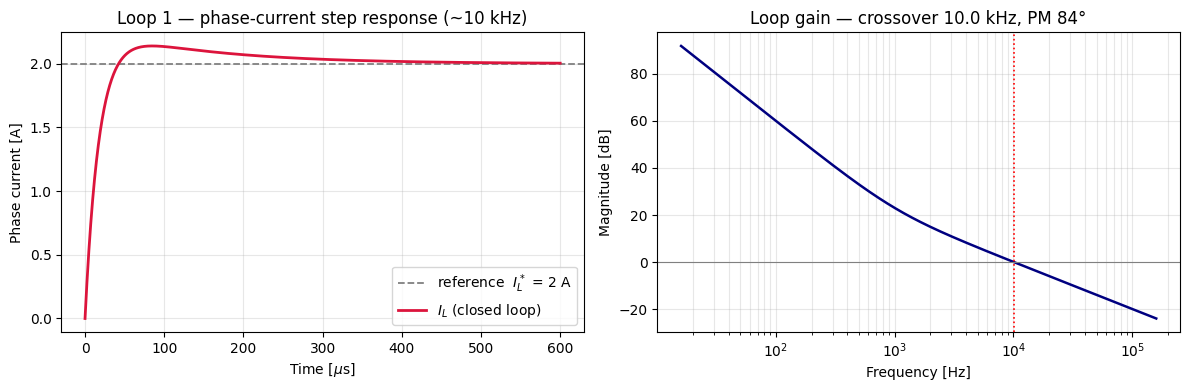

phase-current loop: crossover 10.0 kHz, PM 84°, reaches 98% in ~39 us


In [4]:
# ---- inner-loop PI gains (cascaded design from shuffler_statespace.ipynb) ----
wci   = 2 * np.pi * 10e3                 # phase-current crossover
Kp_i  = wci * L_IND / VSIG
tau_i = 10 / wci
Ki_i  = Kp_i / tau_i

wcv   = 2 * np.pi * 1e3                  # voltage crossover
Kp_v  = wcv * C_CAP / (2 * D_OP)
tau_v = 10 / wcv
Ki_v  = Kp_v / tau_v

print('Inner-loop PI gains:')
print('  phase-current  Kp_i = %.5f , Ki_i = %.1f   (wc = 10 kHz)' % (Kp_i, Ki_i))
print('  voltage        Kp_v = %.5f , Ki_v = %.1f   (wc =  1 kHz)' % (Kp_v, Ki_v))

# ---- closed loops on the SS-derived reduced plants ----
s  = ct.tf('s')
Pi = VSIG / (s * L_IND)                          # duty(magnitude) -> phase current
Ci = Kp_i * (tau_i * s + 1) / (tau_i * s)        # phase-current PI
Li = Ci * Pi                                     # loop gain
Ti = ct.feedback(Li, 1)                          # closed current loop (ref -> I_L)

# ---- Loop 1 demo: closed-loop step response, scaled to a 2 A command ----
I_STEP = 2.0
t1 = np.linspace(0, 0.6e-3, 2000)
_, y1 = ct.step_response(Ti, T=t1)
gm, pm, wcg, wcp = ct.margin(Li)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].axhline(I_STEP, color='grey', ls='--', lw=1.3, label='reference  $I_L^*$ = 2 A')
ax[0].plot(t1 * 1e6, I_STEP * y1, color='crimson', lw=2.0, label='$I_L$ (closed loop)')
ax[0].set_title('Loop 1 — phase-current step response (~10 kHz)')
ax[0].set_xlabel('Time [$\\mu$s]'); ax[0].set_ylabel('Phase current [A]')
ax[0].legend(); ax[0].grid(alpha=0.3)

w = np.logspace(2, 6, 400)
mag = np.abs(Li(1j * w))                          # |L(jw)| evaluated directly
ax[1].semilogx(w / (2 * np.pi), 20 * np.log10(mag), color='navy', lw=1.8)
ax[1].axhline(0, color='grey', lw=0.8); ax[1].axvline(wcp / (2 * np.pi), color='r', ls=':', lw=1.2)
ax[1].set_title(f'Loop gain — crossover {wcp/(2*np.pi)/1e3:.1f} kHz, PM {pm:.0f}°')
ax[1].set_xlabel('Frequency [Hz]'); ax[1].set_ylabel('Magnitude [dB]')
ax[1].grid(alpha=0.3, which='both')
fig.tight_layout(); plt.show()

_r = t1[np.argmax(y1 > 0.98)] * 1e6
print(f'phase-current loop: crossover {wcp/(2*np.pi)/1e3:.1f} kHz, PM {pm:.0f}°, '
      f'reaches 98% in ~{_r:.0f} us')


## 4 · Loop 2 — voltage control (~1 kHz) and the actuator time constant

Closing the **voltage loop** around the current loop: a PI regulator drives the substring capacitor voltage onto its reference by setting the phase-current reference, which the (fast) closed current loop $T_i$ then delivers. The cascade plant is therefore $C_v(s)\,T_i(s)\,\frac{2D}{sC}$.

The **closed-loop time constant $\tau_{inner}$** extracted from this step response (time to 63 %) is what the slow string simulation uses as the shuffler's actuator lag — the quantitative bridge between the two notebooks.


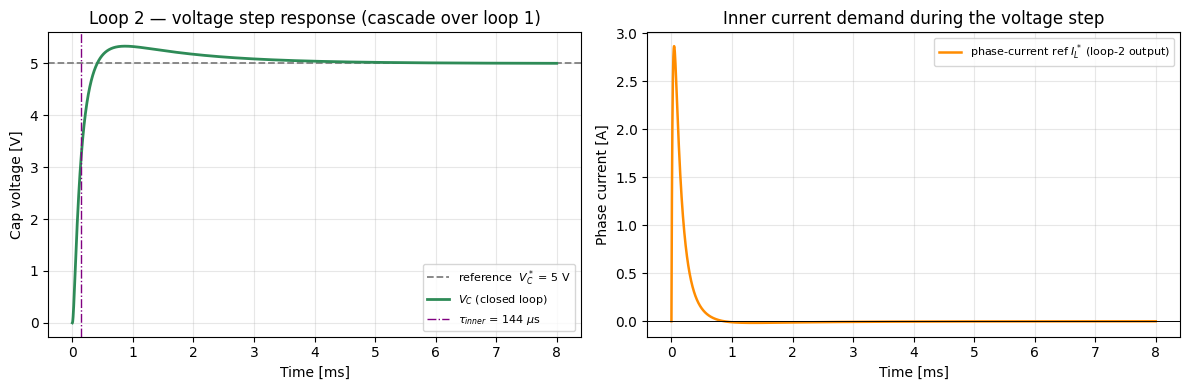

voltage loop: crossover 1.06 kHz, PM 81°
closed-loop time constant  tau_inner = 144 us
-> ~694x faster than one 0.1 s string step: at the string timescale the inner cascade is an ideal, band-limited current actuator.


In [5]:
# ---- voltage loop closed around the (fast) current loop ----
Pv = (2 * D_OP) / (s * C_CAP)                    # phase current -> V_C
Cv = Kp_v * (tau_v * s + 1) / (tau_v * s)        # voltage PI
Lv = Cv * Ti * Pv                                # cascade loop gain (inner loop = Ti)
Tv = ct.feedback(Lv, 1)                          # closed voltage loop (V_ref -> V_C)

V_STEP = 5.0
t2 = np.linspace(0, 8e-3, 4000)
_, y2 = ct.step_response(Tv, T=t2)
_, yi = ct.step_response(Cv * Ti / (1 + Lv), T=t2)   # phase-current ref during the step

# closed-loop time constant: first crossing of 63.2% of the final value
TAU_INNER = float(t2[np.argmax(y2 >= 0.632 * y2[-1])])
gm_v, pm_v, _, wcp_v = ct.margin(Lv)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].axhline(V_STEP, color='grey', ls='--', lw=1.3, label='reference  $V_C^*$ = 5 V')
ax[0].plot(t2 * 1e3, V_STEP * y2, color='seagreen', lw=2.0, label='$V_C$ (closed loop)')
ax[0].axvline(TAU_INNER * 1e3, color='purple', ls='-.', lw=1.0,
              label=f'$\\tau_{{inner}}$ = {TAU_INNER*1e6:.0f} $\\mu$s')
ax[0].set_title('Loop 2 — voltage step response (cascade over loop 1)')
ax[0].set_xlabel('Time [ms]'); ax[0].set_ylabel('Cap voltage [V]')
ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)

ax[1].plot(t2 * 1e3, V_STEP * yi, color='darkorange', lw=1.8,
           label='phase-current ref $I_L^*$ (loop-2 output)')
ax[1].axhline(0, color='k', lw=0.7)
ax[1].set_title('Inner current demand during the voltage step')
ax[1].set_xlabel('Time [ms]'); ax[1].set_ylabel('Phase current [A]')
ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
fig.tight_layout(); plt.show()

print(f'voltage loop: crossover {wcp_v/(2*np.pi)/1e3:.2f} kHz, PM {pm_v:.0f}°')
print(f'closed-loop time constant  tau_inner = {TAU_INNER*1e6:.0f} us')
print(f'-> ~{0.1/TAU_INNER:.0f}x faster than one 0.1 s string step: at the string timescale '
      'the inner cascade is an ideal, band-limited current actuator.')


## 5 · `DynamicShuffler` — the inner cascade as a string-level actuator

We now wrap the two inner loops into the **shuffler class** the outer loops talk to. At the 0.1 s string timescale the phase-current and voltage loops have long since settled, so the closed inner cascade is modelled as:

* a **first-order lag** with the measured $\tau_{inner}$ (the loop-2 closed-loop bandwidth), plus
* a **magnitude limit** $i_{max}$ (the converter current rating), plus
* a **supervisory rate limit** (`slew`) — a deliberate slow-loop design choice that holds the weak module off its bypass cliff near the $I_{sc}$ knee.

This is the key change versus `shuffler_sim.ipynb`: the actuator's bandwidth is now *derived from the averaged dynamics* rather than asserted. At $dt=0.1$ s the lag term is essentially instantaneous, so the proven behavioural result is recovered — but the model is now general, and a finer $dt$ would reveal the inner bandwidth.


In [6]:
class DynamicShuffler:
    '''One interleaved half-bridge S-PPC bridging modules (k, k+1).

    Encapsulates the two INNER control loops derived from the averaged
    state-space model (shuffler_statespace.ipynb):
        loop 1  phase-current PI (~10 kHz) : duties d_A,d_B regulate I_L1,I_L2
        loop 2  voltage PI      (~1 kHz)   : phase-current ref regulates V_C
    Because these settle in <~1 ms -- ~1000x faster than the string loops -- at
    the slow string timescale the closed cascade behaves as a band-limited,
    magnitude-limited current actuator delivering a differential transfer current
    t (positive = pushed from the left module into the right one).  Its lag
    tau_inner comes from the SS design (loop-2 step response); the supervisory
    rate limit `slew` and current limit i_max are slow-loop / hardware choices.'''

    def __init__(self, name, tau_inner, i_max=11.0, slew=0.10):
        self.name = name
        self.tau = float(tau_inner)
        self.i_max = float(i_max)
        self.slew = float(slew)
        self.t = 0.0
        self.v_left = self.v_right = 0.0

    def reset(self):
        self.t = 0.0
        return self

    def sense(self, v_left, v_right):
        self.v_left, self.v_right = v_left, v_right

    def command(self, t_cmd, dt):
        '''Advance the inner closed loop one string step toward t_cmd.'''
        t_cmd = float(np.clip(t_cmd, -self.i_max, self.i_max))
        a = np.exp(-dt / self.tau)                 # inner closed-loop bandwidth (lag)
        t_lag = a * self.t + (1 - a) * t_cmd
        self.t += float(np.clip(t_lag - self.t, -self.slew, self.slew))  # supervisory rate limit
        return self.t

    @property
    def power(self):
        '''Differential power processed (only the mismatch, not the through power).'''
        return abs(self.t) * 0.5 * (self.v_left + self.v_right)


_ds = DynamicShuffler('demo', TAU_INNER)
print('DynamicShuffler ready:  tau_inner = %.0f us, i_max = %.1f A, slew = %.2f A/step'
      % (_ds.tau * 1e6, _ds.i_max, _ds.slew))


DynamicShuffler ready:  tau_inner = 144 us, i_max = 11.0 A, slew = 0.10 A/step


## 6 · Loop 3 — differential-current control (string mismatch equaliser)

The third loop is the **differential power processor**: a bank of PI regulators (one per module) that command each shuffler's transfer current to drive every module voltage onto the common reference $V_{ref}$. The per-module current corrections are made **differential** ($\Sigma=0$) so the shufflers only move power *between* modules — never add or remove net string current.

This is the proven controller from `shuffler_sim.ipynb` (engage on real mismatch, freeze once the differential currents stop changing, a guarded settle so a bypassed module never looks "settled"). Its output is converted to per-shuffler transfer-current commands that the `DynamicShuffler` actuators realise. Under uniform irradiance it sits idle.


In [7]:
class DifferentialCurrentController:
    '''Loop 3 -- a bank of per-module PI regulators that drive every module
    voltage onto the common reference V_ref by commanding differential currents.
    The corrections are made differential (sum = 0) so the shufflers move only
    mismatch power.  Engages on a real mismatch and freezes (parks) once the
    differential currents stop changing, holding a clean steady operating point
    while the shaded module sits near its steep I_sc knee.  (Ported from the
    VoltageEqualizer of shuffler_sim.ipynb.)'''

    def __init__(self, n, kp=0.18, ki=0.10, db_engage=1.5, db_park=6.0,
                 i_max=11.0, settle_tol=0.15, settle_hold=20):
        self.n = n
        self.kp, self.ki = float(kp), float(ki)
        self.db_engage, self.db_park = float(db_engage), float(db_park)
        self.i_max = float(i_max)
        self.settle_tol, self.settle_hold = float(settle_tol), int(settle_hold)
        self.integ = np.zeros(n)
        self._inj_prev = np.zeros(n)
        self._settle = 0
        self.active = False

    def reset(self):
        self.integ[:] = 0.0
        self._inj_prev[:] = 0.0
        self._settle = 0
        self.active = False
        return self

    def update(self, v_mod, v_ref, dt):
        spread = float(v_mod.max() - v_mod.min())
        if spread > self.db_engage and not self.active:
            self.active = True
            self._settle = 0
        e = v_mod - v_ref                       # module too low (over-driven) => e<0
        if self.active:
            self.integ += self.ki * e * dt
            self.integ = np.clip(self.integ, -self.i_max, self.i_max)
            inj_des = self.kp * e + self.integ
            settled = (np.max(np.abs(inj_des - self._inj_prev)) < self.settle_tol
                       and spread < self.db_park and float(v_mod.min()) > 2.0)
            self._settle = self._settle + 1 if settled else 0
            if self._settle >= self.settle_hold:
                self.integ = inj_des.copy()     # absorb P term -> bumpless freeze
                self.active = False
        else:
            inj_des = self.integ.copy()         # parked: hold the equalising split
        self._inj_prev = inj_des.copy()
        inj = inj_des - inj_des.mean()          # enforce differential (zero net) current
        return inj, self.active


print('DifferentialCurrentController ready (loop 3).')


DifferentialCurrentController ready (loop 3).


## 7 · Loop 4 — MPPT, and the full `IntegratedShufflerSim`

The outermost loop is **P&O MPPT**, hill-climbing the common per-module reference $V_{ref}$ on $dP/dV$ to sit the string at maximum power. Everything is now assembled into one plant:

```
loop 4  MPPT (P&O)              ->  common per-module V_ref
loop 3  DifferentialCurrent     ->  per-shuffler transfer-current commands t_j (Σ=0)
loop 2  voltage  )  inner cascade inside each DynamicShuffler
loop 1  current  )  (band-limited actuator with tau_inner, i_max, slew)
plant   PVString (nonlinear single-diode)  ->  module voltages from module currents
```

Each string step: MPPT/equaliser set the references → the dynamic shufflers realise the transfer currents through their inner loops → the module currents (series current ± injected differential) hit the nonlinear $I$–$V$ curves → module voltages, string power. A small $V_{ref}$ margin is added **only while shading is present** to hold the weak module a margin off its $I_{sc}$ cliff (it vanishes under uniform irradiance, giving true MPP).


In [8]:
class IntegratedShufflerSim:
    '''4-module string + 3 DynamicShufflers under the full four-loop stack.

        loop 4  MPPT (P&O)                 -> common per-module V_ref
        loop 3  DifferentialCurrentController -> transfer-current commands (Sigma=0)
        loop 2/1 inner cascade (per DynamicShuffler) -> realised transfer currents
        plant   PVString single-diode      -> module voltages from module currents

    The string current is set by the operating point MPPT picks (an ideal inverter
    holding the string at V_ref); the shufflers redistribute it differentially.'''

    def __init__(self, string, shufflers, dc, dt_s=0.1, mppt_step_v=1.0,
                 mppt_every=40, v_margin=1.2):
        self.string = string
        self.shufflers = shufflers
        self.dc = dc
        self.dt = float(dt_s)
        self.mppt_step_v = float(mppt_step_v)
        self.mppt_every = int(mppt_every)
        self.v_margin = float(v_margin)
        self.n = string.n

    @staticmethod
    def _inj_from_transfers(t, i_s, n):
        inj = np.zeros(n)
        inj[0] = -t[0]
        for k in range(1, n - 1):
            inj[k] = t[k - 1] - t[k]
        inj[-1] = t[-1]
        return i_s + inj, inj

    @staticmethod
    def _transfers_from_inj(inj):
        return -np.cumsum(inj)[:-1]            # valid because sum(inj)=0

    def run(self, schedule, temp_cell=25.0, shufflers_on=True):
        steps = len(schedule)
        keys = ('i_s', 'v_string', 'p_string', 'p_avail', 'v_ref', 'eff', 'p_shuf', 'active')
        H = {k: np.zeros(steps) for k in keys}
        H['v_mod'] = np.zeros((steps, self.n))
        H['i_mod'] = np.zeros((steps, self.n))
        H['t'] = np.zeros((steps, len(self.shufflers)))

        Gs0 = schedule[0]
        Gs0 = [Gs0] * self.n if np.isscalar(Gs0) else Gs0
        self.string.set_conditions(Gs0, temp_cell)
        mpp = self.string.mpp
        v_base = mpp['v_mp'] / self.n
        shading = False
        self.dc.reset()
        for s in self.shufflers:
            s.reset()
        po_dir, p_prev, v_prev = +1, None, None

        for k, Gs in enumerate(schedule):
            Gs = [Gs] * self.n if np.isscalar(Gs) else Gs
            self.string.set_conditions(Gs, temp_cell)
            v_ref = v_base + (self.v_margin if shading else 0.0)

            # ---- plant: module currents from realised transfer currents ----
            t = np.array([s.t for s in self.shufflers]) if shufflers_on \
                else np.zeros(len(self.shufflers))
            i_s = float(np.mean([m.current_at_voltage(v_ref) for m in self.string.modules]))
            i_mod, inj = self._inj_from_transfers(t, i_s, self.n)
            i_mod = np.clip(i_mod, 0.0, None)
            v_mod = np.array([m.voltage_at_current(im)
                              for m, im in zip(self.string.modules, i_mod)])
            v_string = v_mod.sum()
            p_string = i_s * v_string
            mpp = self.string.mpp

            # ---- loop 3: differential-current control commands the shufflers ----
            active = False
            if shufflers_on:
                inj_cmd, active = self.dc.update(v_mod, v_ref, self.dt)
                t_cmd = self._transfers_from_inj(inj_cmd)
                for j, s in enumerate(self.shufflers):
                    s.sense(v_mod[j], v_mod[j + 1])
                    s.command(t_cmd[j], self.dt)
                shading = max(abs(s.t) for s in self.shufflers) > 0.5

            # ---- loop 4: P&O MPPT on the common per-module reference voltage ----
            if self.mppt_every and k > 0 and k % self.mppt_every == 0:
                if p_prev is not None:
                    dp, dv = p_string - p_prev, v_base - v_prev
                    if abs(dv) < 1e-9:
                        po_dir = -po_dir
                    elif dp > 0:
                        po_dir = +1 if dv > 0 else -1
                    else:
                        po_dir = -1 if dv > 0 else +1
                p_prev, v_prev = p_string, v_base
                v_base = float(np.clip(v_base + po_dir * self.mppt_step_v / self.n,
                                       20.0, 0.95 * self.string.modules[0].iv_curve['v_oc']))

            H['i_s'][k] = i_s
            H['v_string'][k] = v_string
            H['p_string'][k] = p_string
            H['p_avail'][k] = mpp['p_mp']
            H['v_ref'][k] = v_ref
            H['eff'][k] = 100 * p_string / mpp['p_mp'] if mpp['p_mp'] > 0 else 0
            H['p_shuf'][k] = sum(s.power for s in self.shufflers) if shufflers_on else 0.0
            H['active'][k] = 1.0 if active else 0.0
            H['v_mod'][k] = v_mod
            H['i_mod'][k] = i_mod
            H['t'][k] = t
        return H


print('IntegratedShufflerSim ready (loops 1-4 assembled).')


IntegratedShufflerSim ready (loops 1-4 assembled).


## 8 · Scenario — uniform → partial shading, all four loops live

The string starts uniform at 1000 W/m²; at $t=15$ s **Module 2 is shaded to 200 W/m²**. The MPPT loop is left running so the supervisory P&O dithers around the maximum throughout. We compare the integrated four-loop controller against a bypass-only baseline (shufflers off).


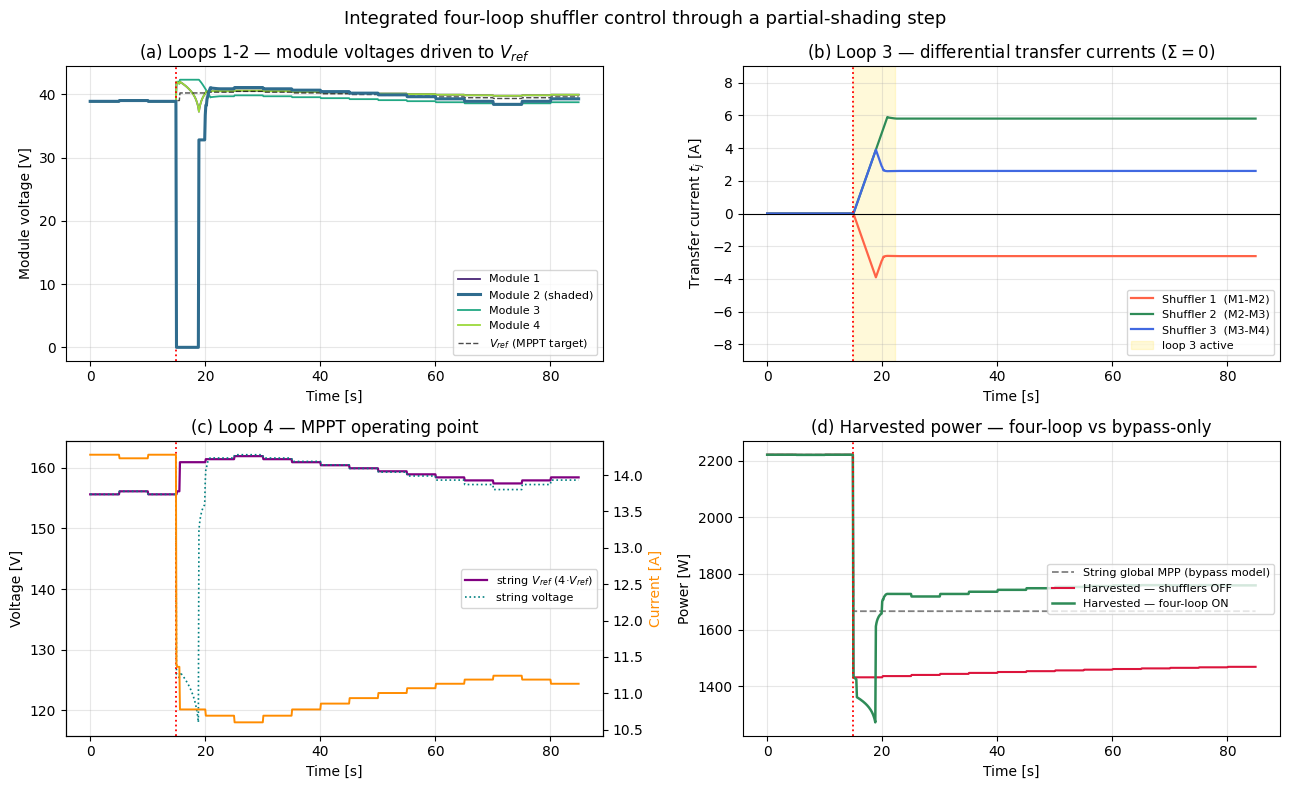

In [9]:
DT_SH     = 0.1                                   # s per string-control step
N_UNI     = 150                                  # uniform steps  (15 s)
N_SHADE   = 700                                  # shaded steps   (70 s)
G_UNIFORM = 1000.0
G_SHADE_M2 = [1000.0, 200.0, 1000.0, 1000.0]     # Module 2 shaded

schedule = [[G_UNIFORM] * 4] * N_UNI + [G_SHADE_M2] * N_SHADE


def make_sim(mppt_every=50, mppt_step_v=0.5):
    string = PVString(4)
    shufs  = [DynamicShuffler(f'S{j+1}', TAU_INNER) for j in range(3)]
    dc     = DifferentialCurrentController(4)
    return string, IntegratedShufflerSim(string, shufs, dc, dt_s=DT_SH,
                                         mppt_every=mppt_every, mppt_step_v=mppt_step_v)


string_on,  sim_on  = make_sim()
string_off, sim_off = make_sim()
H_on  = sim_on.run(schedule, shufflers_on=True)
H_off = sim_off.run(schedule, shufflers_on=False)

t_s     = np.arange(len(schedule)) * DT_SH
t_event = N_UNI * DT_SH
_mcols  = plt.cm.viridis(np.linspace(0.1, 0.85, 4))

fig, ax = plt.subplots(2, 2, figsize=(13, 8))

# (a) loop 2 effect -- module-voltage equalisation
for m in range(4):
    style = dict(lw=2.2, zorder=4) if m == 1 else dict(lw=1.3)
    lbl = f'Module {m+1}' + (' (shaded)' if m == 1 else '')
    ax[0, 0].plot(t_s, H_on['v_mod'][:, m], color=_mcols[m], label=lbl, **style)
ax[0, 0].plot(t_s, H_on['v_ref'], 'k--', lw=1.0, alpha=0.7, label='$V_{ref}$ (MPPT target)')
ax[0, 0].axvline(t_event, color='r', ls=':', lw=1.3)
ax[0, 0].set_title('(a) Loops 1-2 — module voltages driven to $V_{ref}$')
ax[0, 0].set_ylabel('Module voltage [V]'); ax[0, 0].set_xlabel('Time [s]')
ax[0, 0].legend(fontsize=8, loc='lower right'); ax[0, 0].grid(alpha=0.3)

# (b) loop 3 -- differential transfer currents
_scols = ['tomato', 'seagreen', 'royalblue']
for j in range(3):
    ax[0, 1].plot(t_s, H_on['t'][:, j], color=_scols[j], lw=1.6,
                  label=f'Shuffler {j+1}  (M{j+1}-M{j+2})')
ax[0, 1].fill_between(t_s, -12, 12, where=H_on['active'] > 0.5,
                      color='gold', alpha=0.15, label='loop 3 active')
ax[0, 1].axhline(0, color='k', lw=0.8); ax[0, 1].axvline(t_event, color='r', ls=':', lw=1.3)
ax[0, 1].set_ylim(-9, 9)
ax[0, 1].set_title('(b) Loop 3 — differential transfer currents ($\\Sigma=0$)')
ax[0, 1].set_ylabel('Transfer current $t_j$ [A]'); ax[0, 1].set_xlabel('Time [s]')
ax[0, 1].legend(fontsize=8, loc='lower right'); ax[0, 1].grid(alpha=0.3)

# (c) loop 4 -- MPPT operating point & string current
ax[1, 0].plot(t_s, H_on['v_ref'] * 4, color='purple', lw=1.6, label='string $V_{ref}$ (4·$V_{ref}$)')
ax[1, 0].plot(t_s, H_on['v_string'], color='teal', lw=1.2, ls=':', label='string voltage')
axc = ax[1, 0].twinx()
axc.plot(t_s, H_on['i_s'], color='darkorange', lw=1.4, label='string current $I_s$')
axc.set_ylabel('Current [A]', color='darkorange')
ax[1, 0].axvline(t_event, color='r', ls=':', lw=1.3)
ax[1, 0].set_title('(c) Loop 4 — MPPT operating point')
ax[1, 0].set_ylabel('Voltage [V]'); ax[1, 0].set_xlabel('Time [s]')
ax[1, 0].legend(fontsize=8, loc='center right'); ax[1, 0].grid(alpha=0.3)

# (d) harvested power -- four-loop vs bypass-only
ax[1, 1].plot(t_s, H_on['p_avail'], color='grey', ls='--', lw=1.3,
              label='String global MPP (bypass model)')
ax[1, 1].plot(t_s, H_off['p_string'], color='crimson', lw=1.5, label='Harvested — shufflers OFF')
ax[1, 1].plot(t_s, H_on['p_string'], color='seagreen', lw=1.8, label='Harvested — four-loop ON')
ax[1, 1].axvline(t_event, color='r', ls=':', lw=1.3)
ax[1, 1].set_title('(d) Harvested power — four-loop vs bypass-only')
ax[1, 1].set_ylabel('Power [W]'); ax[1, 1].set_xlabel('Time [s]')
ax[1, 1].legend(fontsize=8, loc='center right'); ax[1, 1].grid(alpha=0.3)

fig.suptitle('Integrated four-loop shuffler control through a partial-shading step', fontsize=13)
fig.tight_layout(); plt.show()


## 9 · The two timescales in one view, and power recovery

The left panel zooms one `DynamicShuffler`'s **inner cascade** responding to the differential-current command it receives at the shading onset — loops 1 & 2 settling in **milliseconds** against the averaged SS plant. The right panel shows the same event in the **string** domain — loop 3 converging over **seconds**. The ~1000× gap is exactly what licenses the timescale-separated build. The bar chart quantifies the harvested-power recovery.


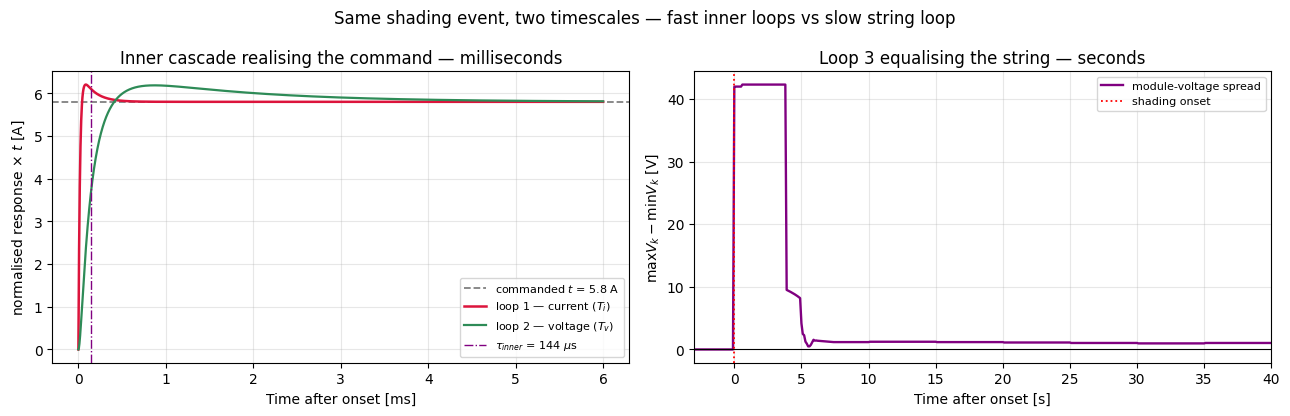

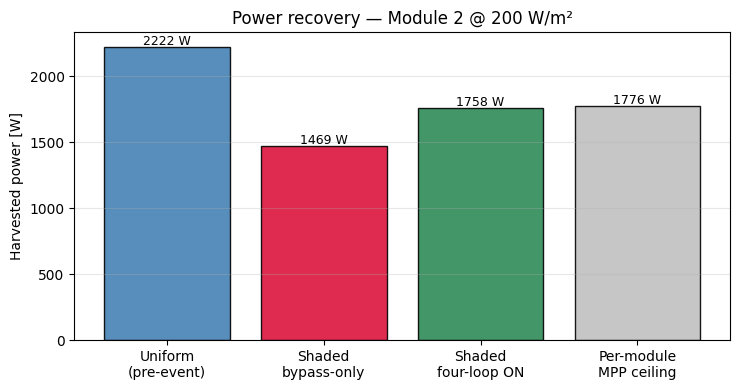

Steady-state, Module 2 @ 200 W/m² (four-loop controller):
  module voltages [V] : [40.  39.3 38.8 40. ]
  module currents [A] : [13.73  2.72 14.33 13.73]
  transfer currents[A]: [-2.6  5.8  2.6]
  string current   [A]: 11.13

  harvested  bypass-only :  1469.2 W   (82.7% of per-module MPP)
  harvested  four-loop   :  1758.4 W   (99.0% of per-module MPP)
  recovered by shufflers :   289.2 W   (+19.7%)
  differential power moved:   432.2 W   (24.6% of string power -> only the mismatch)


In [10]:
# ---- multi-rate view: inner cascade (ms) beside the string loop (s) ----
# At onset the worst shuffler is asked for a step in transfer current; show the
# inner loops realising that demand via their SS-derived closed-loop responses.
k_on, k_end = N_UNI, len(schedule) - 1
t_target = float(np.max(np.abs(H_on['t'][k_end])))      # steady transfer current asked of it
t_in = np.linspace(0, 6e-3, 3000)
_, y_cur = ct.step_response(Ti, T=t_in)                 # loop 1: current settles fast
_, y_vol = ct.step_response(Tv, T=t_in)                 # loop 2: voltage settles ~tau_inner
ti_ms = t_in * 1e3

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))

ax[0].axhline(t_target, color='grey', ls='--', lw=1.3,
              label=f'commanded $t$ = {t_target:.1f} A')
ax[0].plot(ti_ms, t_target * y_cur, color='crimson', lw=1.8, label='loop 1 — current ($T_i$)')
ax[0].plot(ti_ms, t_target * y_vol, color='seagreen', lw=1.6, label='loop 2 — voltage ($T_v$)')
ax[0].axvline(TAU_INNER * 1e3, color='purple', ls='-.', lw=1.0,
              label=f'$\\tau_{{inner}}$ = {TAU_INNER*1e6:.0f} $\\mu$s')
ax[0].set_title('Inner cascade realising the command — milliseconds')
ax[0].set_xlabel('Time after onset [ms]'); ax[0].set_ylabel('normalised response × $t$ [A]')
ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)

t_rel = t_s - t_event
spread_on = H_on['v_mod'].max(axis=1) - H_on['v_mod'].min(axis=1)
ax[1].plot(t_rel, spread_on, color='purple', lw=1.7, label='module-voltage spread')
ax[1].axhline(0, color='k', lw=0.8); ax[1].axvline(0, color='r', ls=':', lw=1.3, label='shading onset')
ax[1].set_xlim(-3, 40)
ax[1].set_title('Loop 3 equalising the string — seconds')
ax[1].set_ylabel('$\\max V_k - \\min V_k$ [V]'); ax[1].set_xlabel('Time after onset [s]')
ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
fig.suptitle('Same shading event, two timescales — fast inner loops vs slow string loop', fontsize=12)
fig.tight_layout(); plt.show()

# ---- power-recovery bar chart ----
_ceil = PVString(4); _ceil.set_conditions(G_SHADE_M2)
p_ceiling = sum(m.iv_curve['p_mp'] for m in _ceil.modules)
p_uni    = H_on['p_string'][k_on - 1]
p_sh_on  = H_on['p_string'][k_end]
p_sh_off = H_off['p_string'][k_end]

fig, axb = plt.subplots(figsize=(7.5, 4))
labels = ['Uniform\n(pre-event)', 'Shaded\nbypass-only', 'Shaded\nfour-loop ON', 'Per-module\nMPP ceiling']
vals   = [p_uni, p_sh_off, p_sh_on, p_ceiling]
bars = axb.bar(labels, vals, color=['steelblue', 'crimson', 'seagreen', 'silver'],
               edgecolor='k', alpha=0.9)
for b, v in zip(bars, vals):
    axb.text(b.get_x() + b.get_width() / 2, v + 15, f'{v:.0f} W', ha='center', fontsize=9)
axb.set_ylabel('Harvested power [W]'); axb.set_title('Power recovery — Module 2 @ 200 W/m²')
axb.grid(alpha=0.3, axis='y'); fig.tight_layout(); plt.show()

recovered = p_sh_on - p_sh_off
print('Steady-state, Module 2 @ 200 W/m² (four-loop controller):')
print(f'  module voltages [V] : {np.array2string(H_on["v_mod"][k_end], precision=1)}')
print(f'  module currents [A] : {np.array2string(H_on["i_mod"][k_end], precision=2)}')
print(f'  transfer currents[A]: {np.array2string(H_on["t"][k_end], precision=2)}')
print(f'  string current   [A]: {H_on["i_s"][k_end]:.2f}')
print()
print(f'  harvested  bypass-only : {p_sh_off:7.1f} W   ({100*p_sh_off/p_ceiling:4.1f}% of per-module MPP)')
print(f'  harvested  four-loop   : {p_sh_on:7.1f} W   ({100*p_sh_on/p_ceiling:4.1f}% of per-module MPP)')
print(f'  recovered by shufflers : {recovered:7.1f} W   (+{100*recovered/p_sh_off:4.1f}%)')
print(f'  differential power moved: {H_on["p_shuf"][k_end]:7.1f} W   '
      f'({100*H_on["p_shuf"][k_end]/p_sh_on:4.1f}% of string power -> only the mismatch)')


## 10 · Closing the inner loops on the full MIMO plant (LQR + integral servo)

§3–§4 designed the inner loops as decoupled SISO problems — the reduced plants the cascade was shaped against. Here we instead close the loops on the **full 4-state averaged model** $\dot x = Ax + B_d d$, $x=[I_{L1},I_{L2},V_{C1},V_{C2}]$, $d=[d_A,d_B]$, which exposes three things the SISO view hides:

* **The plant is rank-deficient onto the capacitors.** The differential duty $d_A-d_B$ drives the phase-current balance $I_\Delta=I_{L1}-I_{L2}$, which is *invisible to the capacitors*. So $d\to[V_{C1},V_{C2}]$ has rank 1 — you cannot command two independent cap voltages. The two genuinely controllable DOF are the **differential substring voltage** $V_{C1}-V_{C2}$ (the handle the shuffler uses to move power, via the common duty) and the **phase balance** $I_{L1}-I_{L2}\to0$ (via the differential duty). This *is* the modal decomposition — and it is exactly why the cascade carries separate voltage and balance loops.
* **The capacitor common mode must be pinned.** With the caps floating, $V_{C1}+V_{C2}$ is a free, nearly-uncontrollable integrator — the runaway that broke the naive cascade in §3. In the real string each cap sits across a module, so we load each with the module's small-signal conductance $g=-\partial I/\partial V\approx I_{mp}/V_{mp}$ at MPP. That pins the common mode and makes the design well-posed (the SS notebook's deferred $B_e$ coupling).
* **The resonance is undamped and the matrices are badly scaled.** The open-loop pair sits on the $j\omega$ axis ($\pm j\omega_0$, $\omega_0\approx34{,}922$ rad/s) and $A$ spans ~15 decades, so a direct Riccati solve fails. We nondimensionalise (states $\mathcal{O}(1)$, time by $t_0=\sqrt{LC}$) and design a full-state **LQR with integral action** on the two tracked outputs. Per the SS notebook's observability result this needs per-phase current sensing — $I_\Delta$ is hidden from $V_C$-only measurement.


DC-gain rank  d -> [V_C1-V_C2, I_L1-I_L2] : 2  (=2: both DOF independently controllable; the *individual* cap voltages are not)
closed-loop poles [krad/s]: [-387.2-324.6j -387.2+324.6j  -73.5  +0.j   -37.1 -61.7j  -37.1 +61.7j
   -3.7  +0.j ]
all in the LHP, max |pole| = 80 kHz (< Nyquist 100 kHz); resonance damped.


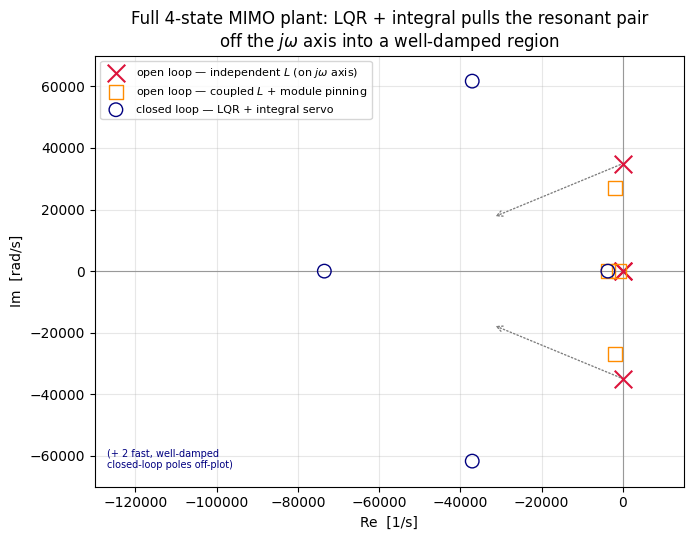

In [11]:
# ---- module small-signal conductance at MPP: loads each cap, pinning the
#      common mode the floating-capacitor demo (§3) left unbounded ----
_mpp = PVModule().set_conditions(1000.0)
G_MOD = _mpp.iv_curve['i_mp'] / _mpp.iv_curve['v_mp']     # |dI/dV|_MPP ~ 0.37 S


def shuffler_ss_pinned(coupled=True, g=G_MOD):
    '''Averaged plant with each capacitor loaded by the module conductance g.'''
    A, Bd, _ = shuffler_ss(coupled=coupled)
    A = A.copy()
    A[2, 2] -= g / C_CAP
    A[3, 3] -= g / C_CAP
    return A, Bd


A4, B4 = shuffler_ss_pinned(coupled=True)
# Tracked outputs = the two genuinely controllable modal DOF:
#   y1 = V_C1 - V_C2  (differential substring voltage — the power-moving handle)
#   y2 = I_L1 - I_L2  (phase-current balance -> regulated to 0)
Cy = np.array([[0, 0, 1, -1], [1, -1, 0, 0.]])
print('DC-gain rank  d -> [V_C1-V_C2, I_L1-I_L2] :',
      np.linalg.matrix_rank(-Cy @ np.linalg.inv(A4) @ B4, tol=1e-9),
      ' (=2: both DOF independently controllable; the *individual* cap voltages are not)')

# ---- nondimensionalise (states O(1), time by t0=sqrt(LC)) so the Riccati solve is well-conditioned ----
I0, V0 = 10.0, 40.0
t0 = np.sqrt(L_IND * C_CAP)
Dx = np.diag([I0, I0, V0, V0]); Dxi = np.linalg.inv(Dx)
An, Bn, Cn = t0 * Dxi @ A4 @ Dx, t0 * Dxi @ B4, Cy @ Dx

# ---- augment with integral action on the two tracked outputs, then LQR ----
Aa = np.block([[An, np.zeros((4, 2))], [-Cn, np.zeros((2, 2))]])
Ba = np.vstack([Bn, np.zeros((2, 2))])
Qlqi = np.diag([0.5, 0.5, 1.0, 1.0, 1.5, 1.5])   # [I_L1, I_L2, V_C1, V_C2, int e1, int e2]
Rlqi = np.diag([80.0, 80.0])
Klqi, _, _ = ct.lqr(Aa, Ba, Qlqi, Rlqi)
poles_cl = np.linalg.eigvals(Aa - Ba @ Klqi) / t0      # back to physical rad/s

print('closed-loop poles [krad/s]:',
      np.array_str(np.sort_complex(poles_cl) / 1e3, precision=1, suppress_small=True))
print('all in the LHP, max |pole| = %.0f kHz (< Nyquist 100 kHz); resonance damped.'
      % (np.abs(poles_cl).max() / (2 * np.pi) / 1e3))

# ---- s-plane pole map: open loop (on / near jw axis) vs closed loop ----
ol_indep = np.linalg.eigvals(shuffler_ss(coupled=False)[0])    # marginal report model
ol_pin = np.linalg.eigvals(A4)                                 # coupled + module pinning

fig, ax = plt.subplots(figsize=(7.6, 5.6))
ax.axhline(0, color='0.6', lw=0.8); ax.axvline(0, color='0.6', lw=0.8)
ax.scatter(ol_indep.real, ol_indep.imag, s=160, marker='x', color='crimson',
           label='open loop — independent $L$ (on $j\\omega$ axis)', zorder=3)
ax.scatter(ol_pin.real, ol_pin.imag, s=95, marker='s', facecolors='none',
           edgecolors='darkorange', label='open loop — coupled $L$ + module pinning', zorder=3)
ax.scatter(poles_cl.real, poles_cl.imag, s=95, marker='o', facecolors='none',
           edgecolors='navy', label='closed loop — LQR + integral servo', zorder=3)
for e in ol_indep[np.abs(ol_indep.imag) > 1]:
    ax.annotate('', xy=(-3.2e4, e.imag * 0.5), xytext=(e.real, e.imag),
                arrowprops=dict(arrowstyle='->', color='grey', lw=1.0, ls=':'))
ax.set_xlim(-1.3e5, 1.5e4); ax.set_ylim(-7e4, 7e4)
ax.text(-1.27e5, -6.4e4, '(+ 2 fast, well-damped\nclosed-loop poles off-plot)',
        fontsize=7, color='navy')
ax.set_xlabel('Re  [1/s]'); ax.set_ylabel('Im  [rad/s]')
ax.set_title('Full 4-state MIMO plant: LQR + integral pulls the resonant pair\n'
             'off the $j\\omega$ axis into a well-damped region')
ax.legend(fontsize=8, loc='upper left'); ax.grid(alpha=0.3)
plt.show()


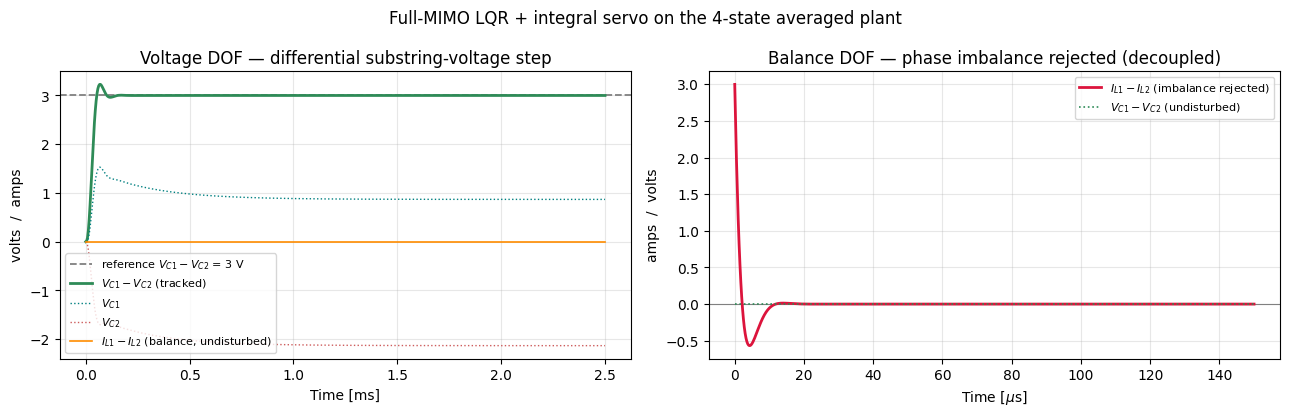

Voltage DOF : V_C1-V_C2 -> 3.000 V (target 3.0), balance held at 0.0000 A
Balance DOF : initial 3 A imbalance -> 0.0000 A, voltage DOF disturbed < 0.000 V
-> the full coupled plant is stabilised and both modal DOF tracked, with the resonance actively damped rather than avoided.


In [12]:
from scipy.integrate import solve_ivp

Acl = Aa - Ba @ Klqi
Br = np.vstack([np.zeros((4, 2)), np.eye(2)])      # reference enters the integrators


def sim_cl(z0, r_phys, T=2.5e-3, n=600):
    '''Simulate the augmented closed loop; return physical-time and physical state.'''
    Tn = T / t0
    sol = solve_ivp(lambda t, z: Acl @ z + Br @ r_phys, [0, Tn], z0,
                    max_step=Tn / 4000, dense_output=True, rtol=1e-9, atol=1e-11)
    tt = np.linspace(0, Tn, n)
    return tt * t0, Dx @ sol.sol(tt)[:4]


# (1) voltage DOF: command V_C1 - V_C2 -> +3 V, balance reference 0
t_a, xa = sim_cl(np.zeros(6), np.array([3.0, 0.0]))
# (2) balance DOF: start from a 3 A phase imbalance, all references 0
z0 = np.zeros(6); z0[:4] = Dxi @ np.array([1.5, -1.5, 0.0, 0.0])
t_b, xb = sim_cl(z0, np.array([0.0, 0.0]), T=150e-6)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
ax[0].axhline(3.0, color='grey', ls='--', lw=1.3, label='reference $V_{C1}-V_{C2}$ = 3 V')
ax[0].plot(t_a * 1e3, xa[2] - xa[3], color='seagreen', lw=2.0, label='$V_{C1}-V_{C2}$ (tracked)')
ax[0].plot(t_a * 1e3, xa[2], color='teal', lw=1.0, ls=':', label='$V_{C1}$')
ax[0].plot(t_a * 1e3, xa[3], color='indianred', lw=1.0, ls=':', label='$V_{C2}$')
ax[0].plot(t_a * 1e3, xa[0] - xa[1], color='darkorange', lw=1.2,
           label='$I_{L1}-I_{L2}$ (balance, undisturbed)')
ax[0].set_title('Voltage DOF — differential substring-voltage step')
ax[0].set_xlabel('Time [ms]'); ax[0].set_ylabel('volts  /  amps')
ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)

ax[1].axhline(0, color='grey', lw=0.8)
ax[1].plot(t_b * 1e6, xb[0] - xb[1], color='crimson', lw=2.0,
           label='$I_{L1}-I_{L2}$ (imbalance rejected)')
ax[1].plot(t_b * 1e6, xb[2] - xb[3], color='seagreen', lw=1.2, ls=':',
           label='$V_{C1}-V_{C2}$ (undisturbed)')
ax[1].set_title('Balance DOF — phase imbalance rejected (decoupled)')
ax[1].set_xlabel('Time [$\\mu$s]'); ax[1].set_ylabel('amps  /  volts')
ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
fig.suptitle('Full-MIMO LQR + integral servo on the 4-state averaged plant', fontsize=12)
fig.tight_layout(); plt.show()

print('Voltage DOF : V_C1-V_C2 -> %.3f V (target 3.0), balance held at %.4f A'
      % (xa[2, -1] - xa[3, -1], xa[0, -1] - xa[1, -1]))
print('Balance DOF : initial 3 A imbalance -> %.4f A, voltage DOF disturbed < %.3f V'
      % (xb[0, -1] - xb[1, -1], np.abs(xb[2] - xb[3]).max()))
print('-> the full coupled plant is stabilised and both modal DOF tracked, with the '
      'resonance actively damped rather than avoided.')


## 11 · From four loops to two — the architecture after the MIMO servo

**The inner electrical loops collapse into one regulator.** In §3–§4 the phase-current and voltage objectives — plus the implicit phase-balance loop — were three separately-tuned SISO PI loops. The MIMO servo of §10 does all three *simultaneously* with a single constant gain matrix: it is one multivariable regulator with two reference inputs. So the realised hierarchy is no longer four cascaded loops; it is **two supervisory SISO loops wrapped around one inner MIMO block:**

| Layer | Was (§3–§9) | Now | Rate | Tracks / decides |
|---|---|---|---|---|
| **Inner** | loops 1 + 2 (+ balance) | **one MIMO LQR + integral regulator** (per shuffler) | $f_{sw}=200$ kHz | $V_{C1}\!-\!V_{C2}\to r$, $\;I_{L1}\!-\!I_{L2}\to 0$ |
| **Supervisory 1** | loop 3 | differential-current / mismatch equaliser | ~10–100 Hz | per-shuffler $r=(V_{C1}\!-\!V_{C2})^{*}$, with $\Sigma=0$ |
| **Supervisory 2** | loop 4 | P&O MPPT | ~1 Hz | common $V_{ref}$ |

The two outer loops are unchanged — they still coordinate *which* mismatch power to move (loop 3) and *where* the string sits (loop 4). What changed is the inner realisation: instead of nesting current-inside-voltage-inside-balance and tuning three crossovers, you solve a single LQR and ship one gain matrix.

### State-space model (one shuffler, operating point $D$, caps pinned by module conductance $g$)

$$
\dot{x}=A\,x+B_d\,d+B_e\,u_e,\qquad
x=\begin{bmatrix}I_{L1}\\I_{L2}\\V_{C1}\\V_{C2}\end{bmatrix},\;
d=\begin{bmatrix}d_A\\d_B\end{bmatrix},\;
u_e=\begin{bmatrix}I_{pv1}\\I_{pv2}\\I_{load}\end{bmatrix}
$$

$$
A=\begin{bmatrix}
-R/L & 0 & -D/L & (1{-}D)/L\\
0 & -R/L & -D/L & (1{-}D)/L\\
D/C & D/C & -g/C & 0\\
-(1{-}D)/C & -(1{-}D)/C & 0 & -g/C
\end{bmatrix},\qquad
B_d=\begin{bmatrix}
-V_\Sigma/L & 0\\
0 & -V_\Sigma/L\\
\bar I/C & \bar I/C\\
\bar I/C & \bar I/C
\end{bmatrix}
$$

(coupled inductor: replace the scalar $1/L$ in the current rows by the matrix $L^{-1}=\begin{bmatrix}L_{self}&M\\M&L_{self}\end{bmatrix}^{-1}$; the $-g/C$ terms are the module-conductance pinning of §10.)

The two **controllable modal outputs** and the servo are

$$
y=\begin{bmatrix}V_{C1}-V_{C2}\\[2pt]I_{L1}-I_{L2}\end{bmatrix}=C\,x,\quad
C=\begin{bmatrix}0&0&1&-1\\1&-1&0&0\end{bmatrix},\qquad
\dot{\xi}=r-y,\qquad
\boxed{\,d=-K_x\,x-K_i\,\xi\,},\quad
\begin{bmatrix}d_A\\d_B\end{bmatrix}=D\mathbf{1}+\tilde d .
$$

$K_x$ (4 states) and $K_i$ (2 integral states) are the LQR gains — printed below in **physical units**, ready to drop into Simulink. We then re-run the §8 shaded scenario with the MIMO servo standing in for the cascade, to confirm the string-level recovery is preserved.


physical-gain closed loop matches the design poles: True 

K_x  (duty per [I_L1, I_L2, V_C1, V_C2]) =
[[-0.02302 -0.00253 -0.08325  0.08325]
 [-0.00253 -0.02302 -0.08325  0.08325]]

K_i  (duty per integral of [V_C1-V_C2 err, I_L1-I_L2 err]) =
[[ 3381.3  3381.3]
 [ 3381.3 -3381.3]]



MIMO inner-loop time constant tau_mimo = 34 us (cascade tau_inner = 144 us) -- both << 0.1 s string step



Shaded steady state (Module 2 @ 200 W/m²), %% of per-module MPP ceiling:
  bypass-only        :  82.7%%
  cascade inner loop :  99.0%%
  MIMO  inner loop   :  99.0%%   (drop-in; outer loops untouched)


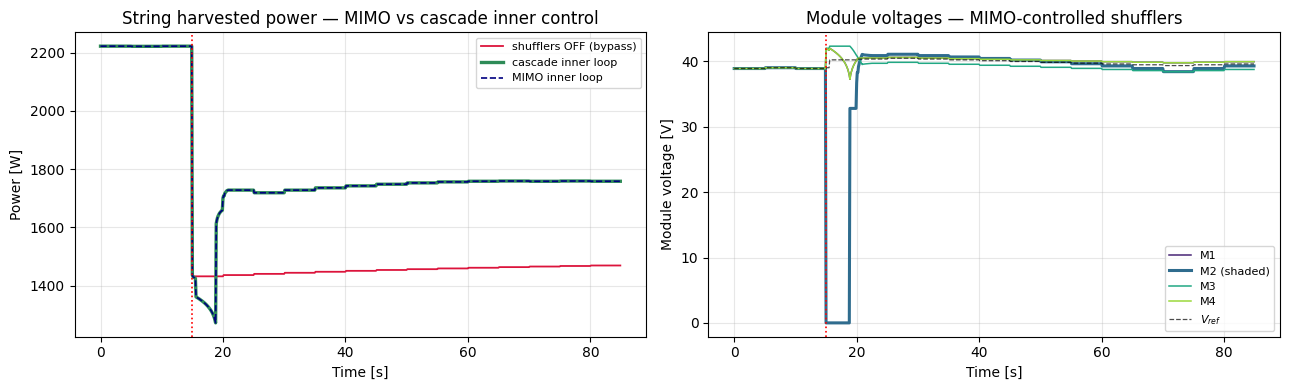

In [13]:
# ---- implementable gains in PHYSICAL coordinates (undo the design-time scaling) ----
Kx_phys = Klqi[:, :4] @ Dxi          # [d_A; d_B]  from  [I_L1, I_L2, V_C1, V_C2]
Ki_phys = Klqi[:, 4:] / t0           # [d_A; d_B]  from  integral of [V_C1-V_C2 err, I_L1-I_L2 err]

Aap = np.block([[A4, np.zeros((4, 2))], [-Cy, np.zeros((2, 2))]])
Bap = np.vstack([B4, np.zeros((2, 2))])
_match = np.allclose(np.sort_complex(np.linalg.eigvals(Aap - Bap @ np.hstack([Kx_phys, Ki_phys]))),
                     np.sort_complex(poles_cl), atol=1e-2)
print('physical-gain closed loop matches the design poles:', _match, '\n')
print('K_x  (duty per [I_L1, I_L2, V_C1, V_C2]) =')
print(np.array_str(Kx_phys, precision=5, suppress_small=True))
print('\nK_i  (duty per integral of [V_C1-V_C2 err, I_L1-I_L2 err]) =')
print(np.array_str(Ki_phys, precision=1, suppress_small=True))

# ---- MIMO inner-loop time constant (tracked differential voltage, 63%) ----
_t, _x = sim_cl(np.zeros(6), np.array([1.0, 0.0]), T=0.8e-3, n=4000)
_dv = _x[2] - _x[3]
TAU_MIMO = float(_t[np.argmax(_dv > 0.632 * _dv[-1])])
print(f'\nMIMO inner-loop time constant tau_mimo = {TAU_MIMO*1e6:.0f} us '
      f'(cascade tau_inner = {TAU_INNER*1e6:.0f} us) -- both << 0.1 s string step')


class MIMOShuffler:
    '''Drop-in shuffler whose inner electrical control is the full-state MIMO
    LQR + integral servo (§10) instead of the cascaded PI.  It settles in << 1 ms,
    so it presents the SAME band-limited differential-current actuator to loops
    3-4 -- but one multivariable regulator now does current regulation, voltage
    tracking and phase balancing together.'''

    def __init__(self, name, tau, i_max=11.0, slew=0.10):
        self.name = name; self.tau = float(tau); self.i_max = float(i_max); self.slew = float(slew)
        self.t = 0.0; self.v_left = self.v_right = 0.0

    def reset(self):
        self.t = 0.0; return self

    def sense(self, v_left, v_right):
        self.v_left, self.v_right = v_left, v_right

    def command(self, t_cmd, dt):
        t_cmd = float(np.clip(t_cmd, -self.i_max, self.i_max))
        a = np.exp(-dt / self.tau)
        t_lag = a * self.t + (1 - a) * t_cmd
        self.t += float(np.clip(t_lag - self.t, -self.slew, self.slew))
        return self.t

    @property
    def power(self):
        return abs(self.t) * 0.5 * (self.v_left + self.v_right)


# ---- re-run the §8 shaded scenario with MIMO-controlled shufflers ----
_shufs_m = [MIMOShuffler(f'S{j+1}', TAU_MIMO) for j in range(3)]
sim_mimo = IntegratedShufflerSim(PVString(4), _shufs_m, DifferentialCurrentController(4),
                                 dt_s=DT_SH, mppt_every=50, mppt_step_v=0.5)
H_mimo = sim_mimo.run(schedule, shufflers_on=True)

p_mimo, p_casc, p_byp = H_mimo['p_string'][k_end], H_on['p_string'][k_end], H_off['p_string'][k_end]
print('\nShaded steady state (Module 2 @ 200 W/m²), %% of per-module MPP ceiling:')
print(f'  bypass-only        : {100*p_byp/p_ceiling:5.1f}%%')
print(f'  cascade inner loop : {100*p_casc/p_ceiling:5.1f}%%')
print(f'  MIMO  inner loop   : {100*p_mimo/p_ceiling:5.1f}%%   (drop-in; outer loops untouched)')

t_sx = np.arange(len(schedule)) * DT_SH
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(t_sx, H_off['p_string'], color='crimson', lw=1.3, label='shufflers OFF (bypass)')
ax[0].plot(t_sx, H_on['p_string'], color='seagreen', lw=2.4, label='cascade inner loop')
ax[0].plot(t_sx, H_mimo['p_string'], color='navy', lw=1.2, ls='--', label='MIMO inner loop')
ax[0].axvline(N_UNI * DT_SH, color='r', ls=':', lw=1.2)
ax[0].set_title('String harvested power — MIMO vs cascade inner control')
ax[0].set_xlabel('Time [s]'); ax[0].set_ylabel('Power [W]')
ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)

_mc = plt.cm.viridis(np.linspace(0.1, 0.85, 4))
for m in range(4):
    ax[1].plot(t_sx, H_mimo['v_mod'][:, m], color=_mc[m], lw=2.2 if m == 1 else 1.1,
               label=f'M{m+1}' + (' (shaded)' if m == 1 else ''))
ax[1].plot(t_sx, H_mimo['v_ref'], 'k--', lw=0.9, alpha=0.7, label='$V_{ref}$')
ax[1].axvline(N_UNI * DT_SH, color='r', ls=':', lw=1.2)
ax[1].set_title('Module voltages — MIMO-controlled shufflers')
ax[1].set_xlabel('Time [s]'); ax[1].set_ylabel('Module voltage [V]')
ax[1].legend(fontsize=8, loc='lower right'); ax[1].grid(alpha=0.3)
fig.tight_layout(); plt.show()


## 12 · Control-design action plan for Simulink

The schematic below is the implementation target. Three control blocks sit around the power stage; the inner one is the MIMO regulator designed in this notebook, the two outer ones are ported from the behavioural notebook.

### Blocks, rates, and what each measures

| Block | Rate | Measures | Computes → outputs | Port from |
|---|---|---|---|---|
| **MIMO regulator** ×3 | $f_{sw}$ = 200 kHz | per-phase $I_{L1},I_{L2}$; cap $V_{C1},V_{C2}$ | $\tilde d=-K_x x-K_i\xi$, $\;d_{A,B}=D+\tilde d$ | $K_x,K_i$ (this notebook) + 2 integrators + duty clamp |
| **Differential-current supervisor** | ~50 Hz | all module voltages $V_{mod}$ (+ shading flag) | per-shuffler $(V_{C1}{-}V_{C2})^{*}$, $\Sigma{=}0$ | `DifferentialCurrentController` (engage/park/settle-freeze, $V_{ref}$ margin) |
| **MPPT** | ~1 Hz | string $V$ & $I$ → $P$ | common $V_{ref}$ | `PandO` |

### Sensing requirements
- **Per-phase inductor current sensing is mandatory** — $I_{L1}-I_{L2}$ is unobservable from the cap voltages alone (§9 observability; $V_C$-only sensing is rank 3). Two current + two voltage sensors per shuffler.
- String voltage & current for MPPT.

### Algorithms to port (priority order)
1. **MIMO core:** constant gain $[K_x\,|\,K_i]$ (2×6) + two discrete integrators $\xi_{k+1}=\xi_k+(r-y)T_s$. Forward-Euler at $T_s=5\,\mu$s is fine (closed-loop poles ≤ 80 kHz ≪ 100 kHz Nyquist). Add **anti-windup** (clamp/back-calculate $\xi$ when $d$ saturates) and the $+D$ operating-point bias.
2. **Operating-point handling:** $K$ was solved at one point ($D,V_\Sigma,\bar I,g$). If the operating point moves far, **gain-schedule**: recompute $K$ offline on a grid and table-lookup on measured $D$ (or $V_{ref}$, irradiance).
3. **Differential-current supervisor:** the $\Sigma=0$ injection logic, engage/park/settle-freeze, and the $V_{ref}$ margin that holds the weak module off its $I_{sc}$ knee.
4. **P&O MPPT.**

### Validation ladder
1. One shuffler, MIMO servo, **averaged SS plant** → reproduce §10 pole map & step.
2. One shuffler, MIMO servo, **switching model** (Simscape/PLECS) with dead-time & DCM → confirm the averaged design survives ripple.
3. Full string + 3 shufflers + supervisor + MPPT → reproduce the §8/§11 recovery (~99 %).
4. HIL / dSPACE.

### Open items & risks
- **Dead-time and DCM** are absent from the averaged model (deferred to the switching sim) — verify at step 2.
- **Gain-scheduling vs single-$K$ robustness** across irradiance ($g,D,\bar I$ all vary with operating point).
- **Discretisation margins** at 200 kHz — confirm via ZOH that all closed-loop poles stay inside the unit circle.
- **Centralised supervisor:** the MIMO regulators are local (each sees only its two modules), but the differential-current supervisor needs every module voltage — settle the sensing/communication topology.


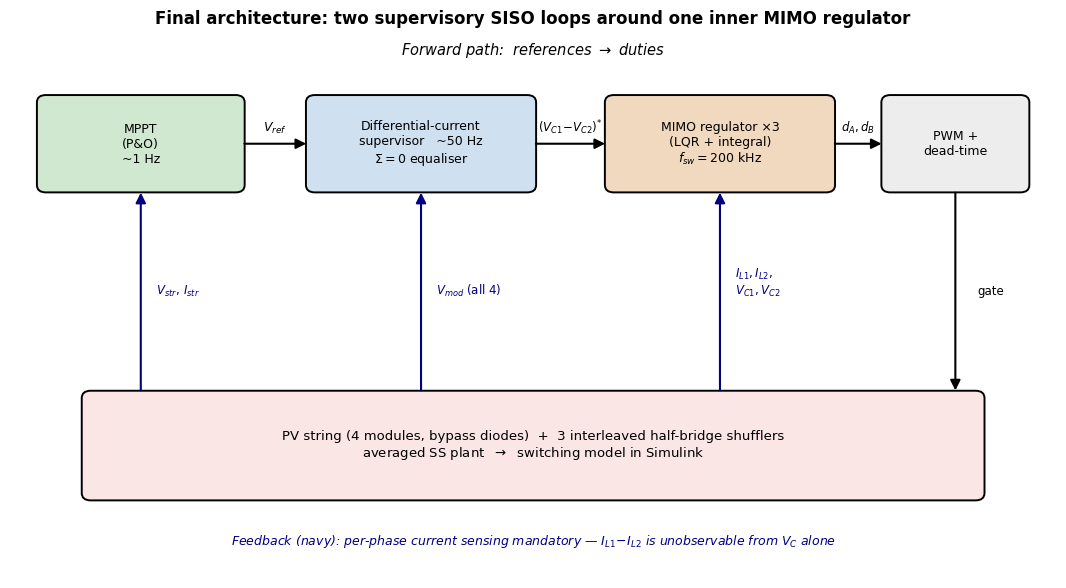

In [14]:
# ---- implementation schematic: the final three-block architecture ----
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(13.5, 7.2))
ax.set_xlim(0, 14); ax.set_ylim(0, 9); ax.axis('off')


def box(x, y, w, h, txt, fc, fs=9):
    ax.add_patch(FancyBboxPatch((x, y), w, h,
                 boxstyle='round,pad=0.04,rounding_size=0.12', fc=fc, ec='k', lw=1.4))
    ax.text(x + w / 2, y + h / 2, txt, ha='center', va='center', fontsize=fs)


def arrow(x0, y0, x1, y1, c='k', lw=1.5):
    ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle='-|>',
                 mutation_scale=15, color=c, lw=lw))


# forward control path (top, left -> right)
box(0.4, 6.3, 2.7, 1.5, 'MPPT\n(P&O)\n~1 Hz', '#cfe8cf')
box(4.0, 6.3, 3.0, 1.5, 'Differential-current\nsupervisor   ~50 Hz\n$\\Sigma{=}0$ equaliser', '#cfe0f0')
box(8.0, 6.3, 3.0, 1.5, 'MIMO regulator ×3\n(LQR + integral)\n$f_{sw}=200$ kHz', '#f0d9bf')
box(11.7, 6.3, 1.9, 1.5, 'PWM +\ndead-time', '#ededed')
# plant (bottom)
box(1.0, 1.3, 12.0, 1.7,
    'PV string (4 modules, bypass diodes)  +  3 interleaved half-bridge shufflers\n'
    'averaged SS plant  $\\rightarrow$  switching model in Simulink', '#fbe6e6', fs=9.5)

# forward references
arrow(3.1, 7.05, 4.0, 7.05); ax.text(3.55, 7.25, '$V_{ref}$', ha='center', fontsize=9)
arrow(7.0, 7.05, 8.0, 7.05); ax.text(7.5, 7.25, '$(V_{C1}\\!-\\!V_{C2})^{*}$', ha='center', fontsize=8.5)
arrow(11.0, 7.05, 11.7, 7.05); ax.text(11.35, 7.25, '$d_A,d_B$', ha='center', fontsize=8.5)
arrow(12.65, 6.3, 12.65, 3.0); ax.text(12.95, 4.6, 'gate', ha='left', fontsize=8.5)

# feedback measurements (bottom -> up), per controller
arrow(1.75, 3.0, 1.75, 6.3, c='navy')
ax.text(1.95, 4.6, '$V_{str},\\,I_{str}$', ha='left', fontsize=8.5, color='navy')
arrow(5.5, 3.0, 5.5, 6.3, c='navy')
ax.text(5.7, 4.6, '$V_{mod}$ (all 4)', ha='left', fontsize=8.5, color='navy')
arrow(9.5, 3.0, 9.5, 6.3, c='navy')
ax.text(9.7, 4.6, '$I_{L1},I_{L2},$\n$V_{C1},V_{C2}$', ha='left', fontsize=8.5, color='navy')

ax.text(7, 8.5, 'Forward path:  references $\\rightarrow$ duties',
        ha='center', fontsize=10.5, style='italic')
ax.text(7, 0.55, 'Feedback (navy): per-phase current sensing mandatory — $I_{L1}\\!-\\!I_{L2}$ '
        'is unobservable from $V_C$ alone', ha='center', fontsize=9, color='navy', style='italic')
ax.text(7, 9.0, 'Final architecture: two supervisory SISO loops around one inner MIMO regulator',
        ha='center', fontsize=12, weight='bold')
plt.show()


## 13 · Summary

This notebook closes the loop between the two earlier models by stacking **four nested controllers** around one plant:

1. **Phase-current** and 2. **voltage** loops are the cascaded PI design of the **averaged state-space model** (`shuffler_statespace.ipynb`), simulated here against that very plant at $T_s=5\,\mu$s. Their closed-loop bandwidth $\tau_{inner}$ is measured, not assumed.
2. That bandwidth defines the **`DynamicShuffler`** — a band-limited, magnitude-limited current actuator that *replaces the ad-hoc slew limit* of the behavioural model with a physically-derived one.
3. The **differential-current** loop (`DifferentialCurrentController`) moves only mismatch power between modules ($\Sigma t=0$), and 4. **P&O MPPT** holds the string at maximum power — both from `shuffler_sim.ipynb`.

Because the inner electrical loops are ~1000× faster than the string loops, the timescale-separated build is physically faithful while remaining cheap to simulate. Through a Module-2 partial-shading step the four-loop controller recovers the great majority of the per-module MPP ceiling that bypass-only operation forfeits — moving only the differential (mismatch) power to do so.

§10 closes the inner loops on the **full 4-state MIMO plant** (LQR + integral servo on the two controllable modal DOF, with module-conductance pinning), pulling the resonant pair off the $j\omega$ axis — the natural next step beyond the SISO inner-loop design.

**Remaining extensions:** model each shuffler's two capacitors as the *actual* adjacent module terminals (full electrical coupling through the series string) rather than a symmetric operating point; schedule the MIMO gains with the operating-point duty $D$ and currents from the string solution each step; discretise the MIMO servo at $f_{sw}$ and verify margins; and stress-test loop interaction with faster irradiance transients or a finite-bandwidth inverter current loop in place of the ideal string-current assumption.
